<a href="https://colab.research.google.com/github/SungJiinwoo/Inteligencia_Artificial_Linguagens_Formais_e_Automatos/blob/main/Unidade5_SistemasEspecialistas/Triagem_Curadoria_TCC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Triagem da fila da curadoria
## Sistema especialista com aprendizado supervisionado aplicado ao Repositório de TCCs (squad 5)

**Inteligência Artificial e LFA | Sistemas Especialistas | Aula 13**

Aluno: João Gabriel Pereira de Araujo · Engenharia de Software · UDF

Adaptei o exemplo do orientador de estudos para o sistema que estou desenvolvendo no squad 5: o repositório público de TCCs dos cursos de TI da UDF. Lá, o orientador ou a coordenação envia o TCC, ele entra como **pendente de análise** e a **curadoria** decide se aprova ou rejeita (RN-07, RN-08).

A ideia aqui é ajudar a curadoria a organizar a fila de pendentes:

* um **modelo supervisionado** olha os metadados da versão enviada e prevê a decisão mais provável (`aprovada` ou `rejeitada`);
* essa previsão vira um **fato**;
* o **sistema especialista** junta esse fato com duas regras que já existem no código do squad 5 e recomenda o que a curadoria deve fazer primeiro.

A decisão continua sendo da curadoria. O sistema só recomenda e explica.

## 0. Estudo inicial (leitura do guia da IBM)

**O que é aprendizado de máquina?**
É a parte da IA em que o algoritmo aprende padrões a partir de dados de treino e depois usa esses padrões para fazer previsões sobre dados novos, sem que alguém escreva as regras na mão.

**O que caracteriza o aprendizado supervisionado?**
Os exemplos de treino já vêm com a resposta certa. O guia chama isso de verdade fundamental. O modelo ajusta seus parâmetros comparando o que previu com essa resposta.

**O que são atributos e rótulos?**
Atributos são as entradas que descrevem o caso. Aqui são a quantidade de palavras do resumo, de palavras-chave, de tecnologias e se tem abstract. O rótulo é a resposta conhecida, a decisão da curadoria.

**Como classificação difere de regressão?**
A classificação prevê uma categoria, como `aprovada` ou `rejeitada`. A regressão prevê um número contínuo, como os dias até a decisão.

**Por que separar treino e teste?**
Para medir o modelo com casos que ele nunca viu. Se eu avaliasse com os mesmos dados do treino, ele poderia só ter decorado os exemplos (overfitting) e eu não ia perceber.

## 1. Preparar o ambiente
No Colab as bibliotecas já vêm instaladas. Se aparecer `ModuleNotFoundError`, rodar `%pip install pandas scikit-learn matplotlib` numa célula nova.

In [1]:
# bibliotecas que vou usar
import pandas as pd                      # tabela com os dados
import matplotlib.pyplot as plt          # gráficos
from datetime import date                # para comparar a data de apresentação com hoje
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

print("Bibliotecas carregadas.")

Bibliotecas carregadas.


## 2. Problema escolhido

| Item | No meu sistema |
|---|---|
| Público | curadoria do repositório de TCCs |
| Entradas do modelo | `palavras_resumo`, `palavras_chave`, `tecnologias`, `tem_abstract` |
| Rótulo previsto | `decisao`: `aprovada` ou `rejeitada` |
| Fatos do sistema | `apresentacao_futura` (RN-41) e `possivel_duplicado` (RN-44) |
| Recomendação | o que a curadoria deve conferir primeiro naquele TCC |

**De onde vem cada entrada no squad 5.** Todas saem do model `Versao` em `tccs/models.py`:

* `resumo` é obrigatório, e eu conto as palavras;
* `palavras_chave` e `tecnologias` são listas que precisam ter pelo menos 1 item cada (`_erros_de_metadados` em `tccs/services.py`, RN-06 e RN-29);
* `abstract` é opcional (`blank=True`), então vira 1 se foi preenchido e 0 se não foi.

O rótulo usa os status que já existem em `StatusVersao`: `aprovada` e `rejeitada`.

## 3. Dataset rotulado

**Tamanho:** 24 exemplos, sendo 12 aprovados e 12 rejeitados.

**Origem:** os dados são **simulados**. O repositório ainda não está em produção, então não existem decisões reais da curadoria para usar. Mesmo quando existirem, os TCCs têm dados pessoais de alunos e orientadores (LGPD), e por isso eu não usaria nome, título nem e-mail. Uso só contagens.

**Critério de rotulagem que eu defini:**

* marquei como `rejeitada` quando o resumo tem menos de 150 palavras, porque a NBR 6028 pede de 150 a 500 palavras em trabalho acadêmico, ou quando tem menos de 3 palavras-chave;
* os outros marquei como `aprovada`;
* coloquei de propósito 2 exceções: a linha 21, rejeitada porque o termo de autorização estava ilegível, e a linha 24, rejeitada porque a monografia estava incompleta. São motivos reais de rejeição que **não aparecem nos atributos**, e quero ver como o modelo se comporta com eles.

In [2]:
# dataset simulado (cada linha é uma versão de TCC que já passou pela curadoria)
dados = pd.DataFrame({
    "palavras_resumo": [220, 180, 310, 250, 160, 400, 275, 195, 350, 210, 170, 290,
                         80, 120,  95, 140,  60, 200, 110, 130, 230,  75, 145, 260],
    "palavras_chave":  [  4,   3,   5,   4,   3,   5,   3,   4,   4,   5,   3,   4,
                          2,   3,   1,   2,   1,   2,   4,   2,   4,   3,   3,   5],
    "tecnologias":     [  2,   1,   3,   2,   2,   4,   1,   3,   2,   2,   3,   1,
                          1,   1,   1,   2,   1,   1,   2,   1,   2,   1,   2,   3],
    "tem_abstract":    [  1,   1,   1,   0,   1,   1,   1,   0,   1,   1,   1,   0,
                          0,   0,   0,   1,   0,   1,   0,   0,   1,   0,   1,   1],
    "decisao": ["aprovada"] * 12 + ["rejeitada"] * 12,
})
dados.index = range(1, len(dados) + 1)   # numerei a partir de 1 para bater com o texto

print(dados.to_string())
print("\nQuantidade por classe:")
print(dados["decisao"].value_counts())

# salvo o dataset em CSV porque ele também faz parte da entrega
dados.to_csv("dataset_triagem_tcc.csv", index_label="linha")

    palavras_resumo  palavras_chave  tecnologias  tem_abstract    decisao
1               220               4            2             1   aprovada
2               180               3            1             1   aprovada
3               310               5            3             1   aprovada
4               250               4            2             0   aprovada
5               160               3            2             1   aprovada
6               400               5            4             1   aprovada
7               275               3            1             1   aprovada
8               195               4            3             0   aprovada
9               350               4            2             1   aprovada
10              210               5            2             1   aprovada
11              170               3            3             1   aprovada
12              290               4            1             0   aprovada
13               80               2   

## 4. Separar treino e teste
`X` fica só com os atributos e `y` com o rótulo. A decisão nunca pode entrar em `X`, senão o modelo receberia a resposta junto com a pergunta.

Reservei 25% para teste: são 18 exemplos de treino e 6 de teste. O `stratify=y` mantém metade de cada classe nos dois grupos, e o `random_state=42` faz a divisão sair sempre igual.

In [3]:
atributos = ["palavras_resumo", "palavras_chave", "tecnologias", "tem_abstract"]
X = dados[atributos]
y = dados["decisao"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Treino:", len(X_treino), "| Teste:", len(X_teste))
print("Linhas que ficaram no teste:", sorted(X_teste.index.tolist()))

Treino: 18 | Teste: 6
Linhas que ficaram no teste: [4, 7, 8, 15, 20, 24]


## 5. Treinar e avaliar
Usei a mesma árvore de decisão da aula, com profundidade máxima 2, para as condições aprendidas continuarem fáceis de ler.

Acurácia no teste: 83.3%
           aprovada  rejeitada
aprovada          3          0
rejeitada         1          2


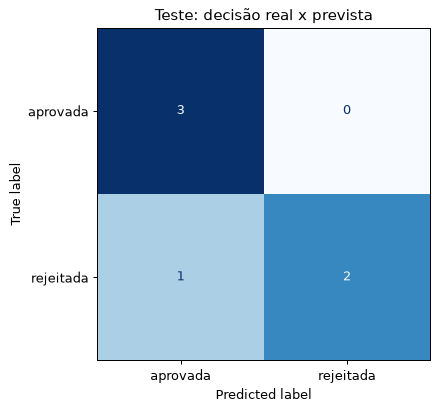

Condições que a árvore aprendeu:
|--- palavras_resumo <= 152.50
|   |--- class: rejeitada
|--- palavras_resumo >  152.50
|   |--- palavras_chave <= 2.50
|   |   |--- class: rejeitada
|   |--- palavras_chave >  2.50
|   |   |--- class: aprovada



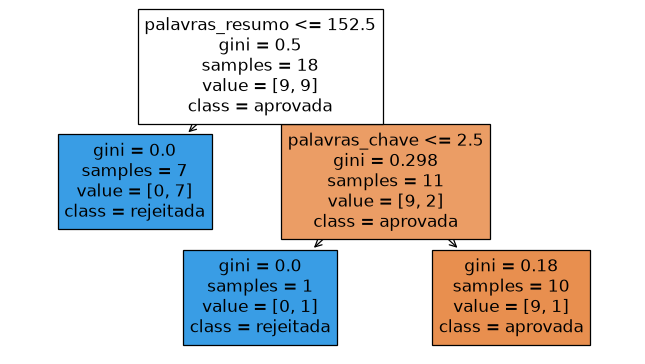

In [4]:
modelo = DecisionTreeClassifier(max_depth=2, random_state=42)
modelo.fit(X_treino, y_treino)            # aprende só com o treino
previsoes = modelo.predict(X_teste)       # prevê os 6 casos de teste

print(f"Acurácia no teste: {accuracy_score(y_teste, previsoes):.1%}")

classes = ["aprovada", "rejeitada"]
matriz = confusion_matrix(y_teste, previsoes, labels=classes)
print(pd.DataFrame(matriz, index=classes, columns=classes))   # linhas = real, colunas = previsto

ConfusionMatrixDisplay(matriz, display_labels=classes).plot(cmap="Blues", colorbar=False)
plt.title("Teste: decisão real x prevista")
plt.show()

print("Condições que a árvore aprendeu:")
print(export_text(modelo, feature_names=atributos))

plt.figure(figsize=(9, 5))
plot_tree(modelo, feature_names=atributos, class_names=list(modelo.classes_), filled=True)
plt.show()

In [5]:
# conferência extra: como o modelo se sai nas duas exceções que eu coloquei (linhas 21 e 24)
excecoes = dados.loc[[21, 24], atributos]
print(pd.DataFrame({
    "real": dados.loc[[21, 24], "decisao"],
    "previsto": modelo.predict(excecoes),
    "estava no": ["teste" if i in X_teste.index else "treino" for i in [21, 24]],
}))

         real  previsto estava no
21  rejeitada  aprovada    treino
24  rejeitada  aprovada     teste


**O que eu tiro disso:**

* A acurácia no teste foi de **83,3%**: 5 acertos em 6. Na matriz, os 3 aprovados foram previstos certo, e 1 dos 3 rejeitados foi previsto como aprovado.
* A árvore aprendeu duas condições: `palavras_resumo <= 152.5` leva a rejeitada, e com resumo maior, `palavras_chave <= 2.5` também leva a rejeitada. São praticamente os critérios que usei para rotular (150 palavras e 3 palavras-chave). Ela não usou `tecnologias` nem `tem_abstract`.
* O único erro foi a **linha 24**, uma das exceções que coloquei de propósito, a da monografia incompleta. A linha 21 ficou no treino, mas a árvore também prevê `aprovada` para ela, porque com profundidade 2 não dá para isolar um caso que foge do padrão.
* Os metadados das duas linhas são bons, e o motivo da rejeição (termo ilegível, monografia incompleta) não está nos atributos. Isso mostra o limite do modelo: ele só enxerga o que entra em `X`.

## 6. Base de conhecimento e motor de inferência

A previsão do modelo vira o fato `previsao`. Os outros dois fatos já são calculados pelo squad 5:

* **`apresentacao_futura`**: em `curadoria/services.py`, a função `_apresentacao_futura` compara `data_apresentacao` com a data de hoje, e `aprovar_tcc` recusa a aprovação enquanto a apresentação não aconteceu (RN-41);
* **`possivel_duplicado`**: `verificar_duplicado` em `tccs/services.py` marca o TCC quando já existe outro com o mesmo título e pelo menos um autor em comum (RN-44).

**Origem das regras:**

* R1 e R2 vêm das regras de negócio que o squad já implementou;
* R3 e R4 usam a previsão e foram escritas por mim, pensando no que a curadoria faz na tela de análise: conferir a monografia e o termo antes de aprovar, e informar o motivo ao rejeitar (RN-09, o motivo é obrigatório).

As regras estão em **ordem de prioridade**, como na aula 12, quando mais de uma regra serve. A data e o duplicado vêm antes da previsão, porque são bloqueios reais do sistema. `None` quer dizer "tanto faz".

In [6]:
regras = [
    {"id": "R1", "apresentacao_futura": True,  "possivel_duplicado": None,  "previsao": None,
     "acao": "Não aprovar ainda: a aprovação fica bloqueada até a data de apresentação (RN-41). "
             "Se houver problema, já pode rejeitar com motivo."},
    {"id": "R2", "apresentacao_futura": False, "possivel_duplicado": True,  "previsao": None,
     "acao": "Comparar com o TCC apontado como possível duplicado antes de decidir (RN-44)."},
    {"id": "R3", "apresentacao_futura": False, "possivel_duplicado": False, "previsao": "aprovada",
     "acao": "Seguir com a análise completa: conferir a monografia e o termo de autorização "
             "antes de aprovar."},
    {"id": "R4", "apresentacao_futura": False, "possivel_duplicado": False, "previsao": "rejeitada",
     "acao": "Conferir resumo e palavras-chave; se estiverem incompletos, rejeitar informando "
             "o motivo (RN-09)."},
]

def aplicar_regras(fatos):
    """Motor: percorre a base na ordem e devolve a primeira regra em que todas as condições batem."""
    for regra in regras:
        condicoes = {k: v for k, v in regra.items() if k not in ("id", "acao") and v is not None}
        if all(fatos[nome] == valor for nome, valor in condicoes.items()):
            return {
                "regra": regra["id"],
                "recomendacao": regra["acao"],
                "explicacao": "fatos usados: " + ", ".join(f"{n}={fatos[n]}" for n in condicoes),
            }
    raise ValueError("Nenhuma regra compatível com os fatos.")

## 7. Integrar o modelo ao sistema especialista
A função recebe os dados de uma versão pendente, calcula os fatos do sistema, pede a previsão ao modelo e chama o motor. Como no exemplo da professora, avisa quando a entrada sai do intervalo que o modelo viu no treino.

In [7]:
def orientar_curadoria(palavras_resumo, palavras_chave, tecnologias, tem_abstract,
                       data_apresentacao, possivel_duplicado, hoje=None):
    # mesmas exigências do envio no squad 5: pelo menos 1 palavra-chave e 1 tecnologia
    if palavras_resumo <= 0:
        raise ValueError("O resumo é obrigatório.")
    if palavras_chave < 1 or tecnologias < 1:
        raise ValueError("Informe pelo menos uma palavra-chave e uma tecnologia.")
    if tem_abstract not in (0, 1) or not isinstance(possivel_duplicado, bool):
        raise ValueError("tem_abstract deve ser 0 ou 1 e possivel_duplicado deve ser True ou False.")

    hoje = hoje or date.today()
    novo = pd.DataFrame([{"palavras_resumo": palavras_resumo, "palavras_chave": palavras_chave,
                          "tecnologias": tecnologias, "tem_abstract": tem_abstract}])

    fatos = {
        "previsao": modelo.predict(novo)[0],                      # fato que vem do modelo
        "apresentacao_futura": data_apresentacao > hoje,          # RN-41
        "possivel_duplicado": possivel_duplicado,                 # RN-44
    }
    resultado = {"previsao_do_modelo": fatos["previsao"], **aplicar_regras(fatos)}

    fora = any(not X_treino[c].min() <= novo[c].iloc[0] <= X_treino[c].max() for c in atributos)
    resultado["aviso"] = ("Entrada fora dos intervalos observados no treino."
                          if fora else "Recomendação de apoio; a decisão é da curadoria (RN-07).")
    return resultado

## 8. Três casos novos
Nenhum deles está no dataset. Fixei `hoje = 16/11/2026` para o resultado não mudar conforme o dia em que o notebook rodar.

In [8]:
HOJE = date(2026, 11, 16)
casos = [
    # (resumo, palavras-chave, tecnologias, abstract, data de apresentação, possível duplicado)
    (240, 4, 2, 1, date(2026, 11, 5), False),
    (90,  2, 1, 0, date(2026, 10, 28), False),
    (300, 5, 3, 1, date(2026, 12, 3), False),
]
for i, caso in enumerate(casos, 1):
    print(f"\nCASO {i}: {caso[0]} palavras no resumo; {caso[1]} palavras-chave; {caso[2]} tecnologias; "
          f"abstract={caso[3]}; apresentação {caso[4]:%d/%m/%Y}; duplicado={caso[5]}")
    for campo, valor in orientar_curadoria(*caso, hoje=HOJE).items():
        print(f"  {campo}: {valor}")


CASO 1: 240 palavras no resumo; 4 palavras-chave; 2 tecnologias; abstract=1; apresentação 05/11/2026; duplicado=False
  previsao_do_modelo: aprovada
  regra: R3
  recomendacao: Seguir com a análise completa: conferir a monografia e o termo de autorização antes de aprovar.
  explicacao: fatos usados: apresentacao_futura=False, possivel_duplicado=False, previsao=aprovada
  aviso: Recomendação de apoio; a decisão é da curadoria (RN-07).

CASO 2: 90 palavras no resumo; 2 palavras-chave; 1 tecnologias; abstract=0; apresentação 28/10/2026; duplicado=False
  previsao_do_modelo: rejeitada
  regra: R4
  recomendacao: Conferir resumo e palavras-chave; se estiverem incompletos, rejeitar informando o motivo (RN-09).
  explicacao: fatos usados: apresentacao_futura=False, possivel_duplicado=False, previsao=rejeitada
  aviso: Recomendação de apoio; a decisão é da curadoria (RN-07).

CASO 3: 300 palavras no resumo; 5 palavras-chave; 3 tecnologias; abstract=1; apresentação 03/12/2026; duplicado=False


**Análise dos três casos:**

* **Caso 1:** o resumo e as palavras-chave estão dentro do que o modelo aprendeu como aprovado. A apresentação já passou e não há duplicado, então a R3 dispara e a curadoria segue com a análise completa.
* **Caso 2:** o resumo tem 90 palavras e só 2 palavras-chave, e o modelo prevê `rejeitada`. Os bloqueios não se aplicam, então a R4 recomenda conferir os metadados e rejeitar com motivo se estiverem incompletos.
* **Caso 3:** o modelo prevê `aprovada`, mas a R1 tem prioridade, porque a apresentação é em 03/12/2026. Mesmo com metadados bons, o sistema não deixa aprovar antes da data, igual ao que o squad 5 faz em `aprovar_tcc`.

## 9. Comparação: mudar só um fato
Peguei o caso 1 e mudei apenas `possivel_duplicado` para `True`. Os números continuam iguais, então a previsão do modelo é a mesma.

In [9]:
original = orientar_curadoria(240, 4, 2, 1, date(2026, 11, 5), False, hoje=HOJE)
duplicado = orientar_curadoria(240, 4, 2, 1, date(2026, 11, 5), True, hoje=HOJE)
print("previsão nos dois:", original["previsao_do_modelo"], "|", duplicado["previsao_do_modelo"])
print("sem duplicado ->", original["regra"], "|", original["recomendacao"])
print("com duplicado ->", duplicado["regra"], "|", duplicado["recomendacao"])

previsão nos dois: aprovada | aprovada
sem duplicado -> R3 | Seguir com a análise completa: conferir a monografia e o termo de autorização antes de aprovar.
com duplicado -> R2 | Comparar com o TCC apontado como possível duplicado antes de decidir (RN-44).


Quem mudou a recomendação foi o **sistema especialista**, não o modelo. A previsão continuou `aprovada`, mas o fato `possivel_duplicado` fez a R2 disparar antes da R3.

## 10. Erros, limitações e cuidados

* **Dados simulados e poucos:** são 24 exemplos e só 6 no teste. Um acerto a mais ou a menos muda a acurácia em quase 17 pontos (1 de 6). Não dá para dizer que o modelo funciona em uso real, e eu não ajustei o modelo para melhorar esse resultado.
* **O modelo só vê o que está em `X`:** as linhas 21 e 24 mostram isso. Termo ilegível e monografia incompleta são motivos reais de rejeição que nenhum atributo captura. Por isso a R3 manda conferir a monografia e o termo mesmo quando a previsão é `aprovada`.
* **Exemplos pouco representados:** não tem nenhum TCC com resumo acima de 400 palavras, nem TCC em inglês ou espanhol (o campo `idioma` existe no squad 5). Também não separei por curso. Casos assim recebem o aviso de "fora do intervalo" ou podem ser previstos errado.
* **O rótulo vem de um critério meu:** como eu mesmo rotulei, a árvore só reaprende o meu critério. Com decisões reais da curadoria, o padrão poderia ser outro.
* **Dados pessoais (LGPD):** não usei nome de aluno, orientador, título nem e-mail. As contagens são suficientes, e o projeto do squad trata LGPD como requisito real. Se um dia fosse usar decisões reais, os dados precisariam ser anonimizados, e o uso precisaria ser combinado com a faculdade.
* **Supervisão humana:** pela RN-07, só a curadoria aprova ou rejeita. Este sistema não decide nada: ele ordena o que conferir e explica qual regra disparou.

**Questões de fechamento da apresentação:**

* *Qual parte aprende com os dados?* A árvore de decisão, que aprendeu limites para o resumo e as palavras-chave.
* *Qual parte aplica as regras humanas do negócio?* O motor `aplicar_regras`, com as regras R1 a R4. Duas vêm direto das regras de negócio do squad 5.
* *Por que 100% de acerto num teste pequeno exige cautela?* Porque poucos casos não representam a realidade. Aqui deu 83,3% em 6 casos, e se a linha 24 tivesse caído no treino daria 100%, sem o modelo ficar melhor. O resultado depende de quais linhas caem no teste.

## Referências
* IBM. Guia de Aprendizado de Máquina: https://www.ibm.com/br-pt/think/machine-learning
* IBM. Aprendizado supervisionado: https://www.ibm.com/br-pt/think/topics/supervised-learning
* scikit-learn. DecisionTreeClassifier e train_test_split (documentação oficial)
* ABNT NBR 6028:2021, Informação e documentação: resumo, resenha e recensão
* Notebook da aula: Aprendizado de Máquina – Introdução (Profa. Kadidja Valéria)
* Documentos do squad 5: `docs/requirements.md` (RN-06, RN-07, RN-09, RN-29, RN-41, RN-44)